# 06 — Probability calibration and approve/cancel policy

The two fitted tree models remain frozen. Compare four score mappings on **calibration only**: identity (no correction), sigmoid, temperature, and isotonic. Three label-stratified folds keep identical V1–V28/Amount groups together. Choose each mapping by out-of-fold Brier score, then fit a selected non-identity mapping on the full calibration set. This split has 28,452 payments and 48 frauds, so method rankings are uncertain. [Protocol](../docs/evaluation-protocol.md) · [Economics](../docs/cost-scenario.md)

The resulting policies are compared on the reused **selection** set. The economic threshold stays at 0.20 for positive amounts: approve a legitimate payment for +25% of Amount; approving fraud loses 100%; cancellation returns zero. Evaluation labels are not read.

In [1]:
from pathlib import Path
import json, os, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
env = os.environ.copy()
env.update(OPENBLAS_NUM_THREADS="1", OMP_NUM_THREADS="1", MLFLOW_DISABLE_AGENT_HINT="1")
run = subprocess.run([sys.executable, str(root / "scripts/run_calibration.py")], cwd=root, env=env, capture_output=True, text=True)
print(run.stdout)
if run.returncode:
    print(run.stderr)
run.check_returncode()

        model   raw_ap chosen_method  policy_ap  raw_brier  policy_brier  raw_profit_per_1000  policy_profit_per_1000  policy_fraud_recall  policy_legit_cancel_rate
random_forest 0.836546      isotonic   0.807070   0.000466      0.000497         21841.443575            21803.084713             0.710526                  0.000094
     lightgbm 0.842098      identity   0.842098   0.000432      0.000432         21829.362509            21829.362509             0.789474                  0.000141
Method-selected policy leader: lightgbm; all development variants leader: ('random_forest', 'raw'). No candidate frozen. Evaluation was not scored.



In [2]:
report = json.loads((root / "reports/calibration-results.json").read_text())
assert not report["metadata"]["evaluation_split_scored"] and not report["candidate_frozen"]
cv = pd.DataFrame([{"model": row["name"], **check} for row in report["results"] for check in row["calibration_cv"]])
display(cv.pivot(index="model", columns="method", values="out_of_fold_brier").round(6))
print("The identity column uses the unchanged model scores. The other columns predict held-out calibration folds; lower Brier is better.")

method,identity,isotonic,sigmoid,temperature
model,,,,
lightgbm,0.000577,0.000659,0.000837,0.000578
random_forest,0.000387,0.000334,0.000416,0.000421


The identity column uses the unchanged model scores. The other columns predict held-out calibration folds; lower Brier is better.


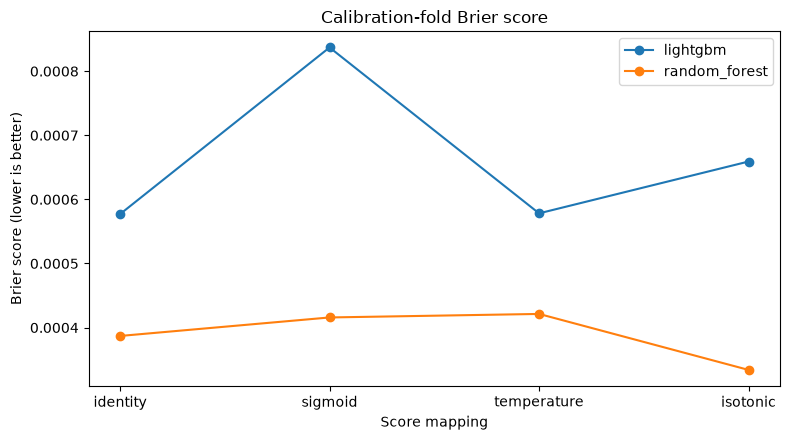

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, group in cv.groupby("model"):
    ax.plot(group.method, group.out_of_fold_brier, marker="o", label=name)
ax.set(title="Calibration-fold Brier score", ylabel="Brier score (lower is better)", xlabel="Score mapping")
ax.legend()
fig.tight_layout()
fig.savefig(root / "reports/figures/calibration-method-brier.png", dpi=160, bbox_inches="tight")
plt.show()

In [4]:
policy_rows = []
for row in report["results"]:
    variants = [("identity (raw)", "selection_policy")] if row["chosen_method"] == "identity" else [("raw", "selection_raw"), (row["chosen_method"], "selection_policy")]
    for mapping, key in variants:
        policy_rows.append({"model": row["name"], "mapping": mapping,
            "average_precision": row[key]["average_precision"], "brier_score": row[key]["brier_score"],
            "fraud_canceled_recall": row[key]["fraud_canceled_recall"],
            "legitimate_cancellation_rate": row[key]["legitimate_cancellation_rate"],
            "profit_per_1000": row[key]["simulated_profit_per_1000"],
            "total_profit": row[key]["simulated_total_profit"]})
comparison = pd.DataFrame(policy_rows)
display(comparison.round(6))
print("Method-selected policy leader:", report["method_selected_policy_profit_leader"])
print("Best observed development profit across raw and method-selected variants:", report["all_development_policy_profit_leader"])
print("No candidate is frozen for evaluation yet.")

,model,mapping,average_precision,brier_score,fraud_canceled_recall,legitimate_cancellation_rate,profit_per_1000,total_profit
0,random_forest,raw,0.836546,0.000466,0.789474,0.000188,21841.443575,931144.4225
1,random_forest,isotonic,0.807070,0.000497,0.710526,0.000094,21803.084713,929509.1075
2,lightgbm,identity (raw),0.842098,0.000432,0.789474,0.000141,21829.362509,930629.3825


Method-selected policy leader: lightgbm
Best observed development profit across raw and method-selected variants: {'model': 'random_forest', 'variant': 'raw'}
No candidate is frozen for evaluation yet.


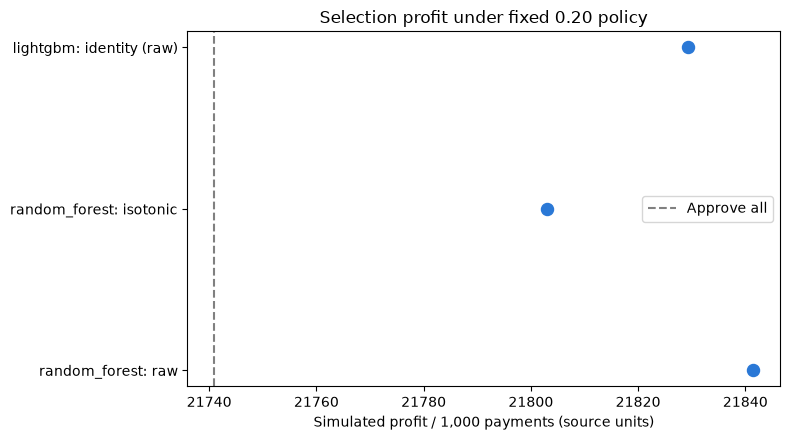

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = [f"{row.model}: {row.mapping}" for row in comparison.itertuples()]
ax.scatter(comparison.profit_per_1000, labels, s=75, color="#2a78d6")
baseline = json.loads((root / "reports/baseline-results.json").read_text())
approve_all_profit = next(row["simulated_profit_per_1000"] for row in baseline["results"] if row["name"] == "approve_all")
ax.axvline(approve_all_profit, color="gray", linestyle="--", label="Approve all")
ax.set(title="Selection profit under fixed 0.20 policy", xlabel="Simulated profit / 1,000 payments (source units)")
ax.legend()
fig.tight_layout()
fig.savefig(root / "reports/figures/calibrated-policy-selection-profit.png", dpi=160, bbox_inches="tight")
plt.show()

## Reliability by score band

The table compares average stated risk with the actual fraud fraction in each selection band. High-risk bands may contain very few payments. Brier and these bins describe probability quality; simulated profit also depends on transaction Amount. Selection has already guided model comparison, so the table is development evidence.

In [6]:
predictions = pd.read_csv(root / report["selection_predictions"]["path"])
breaks = [0, 0.0001, 0.001, 0.01, 0.05, 0.2, 0.5, 1.0000001]
reliability = []
for name, frame in predictions.groupby("model"):
    for mapping, field in [("raw", "raw_probability"), ("selected", "policy_probability")]:
        bands = pd.cut(frame[field], bins=breaks, include_lowest=True)
        bins = frame.groupby(bands, observed=True).agg(payments=("Class", "size"), frauds=("Class", "sum"), mean_score=(field, "mean"))
        for band, row in bins.iterrows():
            reliability.append({"model": name, "mapping": mapping, "score_band": str(band),
                                "payments": int(row.payments), "frauds": int(row.frauds),
                                "mean_score_pct": 100 * row.mean_score,
                                "observed_fraud_pct": 100 * row.frauds / row.payments})
display(pd.DataFrame(reliability).round(3))

,model,mapping,score_band,payments,frauds,mean_score_pct,observed_fraud_pct
0,lightgbm,raw,"(-0.001, 0.0001]",41192,7,0.001,0.017
1,lightgbm,raw,"(0.0001, 0.001]",1187,1,0.026,0.084
2,lightgbm,raw,"(0.001, 0.01]",142,2,0.303,1.408
3,lightgbm,raw,"(0.01, 0.05]",32,3,2.168,9.375
4,lightgbm,raw,"(0.05, 0.2]",9,0,7.143,0.000
5,lightgbm,raw,"(0.2, 0.5]",1,0,36.792,0.000
6,lightgbm,raw,"(0.5, 1.0]",69,63,97.907,91.304
7,lightgbm,selected,"(-0.001, 0.0001]",41192,7,0.001,0.017
8,lightgbm,selected,"(0.0001, 0.001]",1187,1,0.026,0.084
9,lightgbm,selected,"(0.001, 0.01]",142,2,0.303,1.408


**Decision for stage 07:** Random Forest's isotonic mapping leads Brier across calibration folds, but loses selection profit and Brier compared with its raw scores. LightGBM's unchanged scores lead its calibration-fold Brier comparison. Among the method-selected policies, LightGBM leads selection profit; across all observed variants, raw Random Forest leads. These comparisons do not establish a stable winner. Next, compare paired uncertainty on selection and freeze a single candidate **before** any evaluation scoring. A model registry alias or deployment is premature.